# InaCAWO hindcast postprocess — walkthrough & user tutorial

This notebook has two parts:

1. **Part A — Pipeline walkthrough** — how to regrid new hindcast days from `$CAWO_OUTPUT` → `$CAWO_POST` using `run_postprocess.bash`.
2. **Part B — User tutorial** — open, plot, and extract from the shared archive at `/scratch/cawohdcst/data/postprocessed`.

**Kernel:** select the `hindcast` Python kernel in Cursor / Jupyter.

Important: `source setup_env.bash` in a **terminal** does **not** set variables inside this notebook process. The first code cell loads IHT paths into `os.environ` for you.

Sample day used below: **`f19950101`** (exists in the shared archive).


## Part A — Pipeline walkthrough

### Data flow

```
$CAWO_OUTPUT/fYYYYMMDD/
  cawo_g2.8.0_his_*     ──►  post_roms2d / post_roms3d  ──►  $CAWO_POST/ocean{2d,3d}/
  wrfhtr_d01_*          ──►  post_wrf2d                 ──►  $CAWO_POST/wrf2d/
  wrfplev_d01_*         ──►  post_wrf3d                 ──►  $CAWO_POST/wrf3d/
```

All products are regridded with **xesmf** (bilinear) onto **CAWO_LL025**:
`lon ∈ [90, 145]`, `lat ∈ [−15, 15]`, `Δ = 0.025°` → **2201 × 1201** (`COL × ROW`).

### Preferred CLI

```bash
source $HOME/inacawo-iht/setup_env.bash
cd $HOME/inacawo-iht

./run_postprocess.bash --start YYYYMMDD --end YYYYMMDD
./run_postprocess.bash --start YYYYMMDD --end YYYYMMDD --stage roms2d
./run_postprocess.bash --start YYYYMMDD --end YYYYMMDD --stage wrf --dry-run
```

| `--stage` | Expands to |
|-----------|------------|
| `all` (default) | `roms2d,roms3d,wrf2d,wrf3d` |
| `roms` | `roms2d,roms3d` |
| `wrf` | `wrf2d,wrf3d` |

Logs: `$WORK_BASE/logs/postprocess/postprocess_*.log` (terminal prints the realpath).

### Product table

| Stage | Script dir | Input | Output under `$CAWO_POST` | Cadence |
|-------|------------|-------|---------------------------|---------|
| `roms2d` | `postprocess/post_roms2d/` | `cawo_g2.8.0_his_*_XXXXX.nc` | `ocean2d/…/inacawo_hindcast_ocean2d_*.nc` | HIS `1 4 7 … 25` |
| `roms3d` | `postprocess/post_roms3d/` | same his files | `ocean3d/…/inacawo_hindcast_ocean3d_*.nc` | same |
| `wrf2d` | `postprocess/post_wrf2d/` | `wrfhtr_d01_*` | `wrf2d/…/inacawo_hindcast_wrf2d_*.nc` | 3-hourly |
| `wrf3d` | `postprocess/post_wrf3d/` | `wrfplev_d01_*` | `wrf3d/…/post3d_*.nc` | 3-hourly |

Notes:

- WRF stages skip the first 3-hourly file each day (`SKIP_FIRST_3H_INIT=1`) to avoid overlap.
- New WRF3d outputs still use the legacy `post3d_` filename prefix; the **shared archive** uses `inacawo_hindcast_wrf3d_*`.
- Manual fallback: `cd postprocess/post_roms2d && sbatch slurm_run_post_roms2d.bash` (dates via `IHT_START_DATE_ISO` / `IHT_END_DATE_ISO` or script fallbacks).


In [1]:
# Load IHT paths into THIS kernel (terminal `source` does not apply here)
import os
import subprocess
from pathlib import Path

SETUP = Path.home() / "inacawo-iht" / "setup_env.bash"
KEYS = ("WORK_BASE", "CAWO_OUTPUT", "CAWO_POST", "CAWO_HINDCAST_BASE", "SCRATCH")


def load_iht_env(setup_bash: Path = SETUP) -> dict:
    """Source setup_env.bash in bash and import selected exports into os.environ."""
    if not setup_bash.is_file():
        raise FileNotFoundError(setup_bash)
    key_list = " ".join(KEYS)
    # Print KEY=value for each export; use bash nameref ${!k}
    script = (
        "set +e\n"
        + f'source "{setup_bash}" >/dev/null\n'
        + f"for k in {key_list}; do\n"
        + '  v="${!k}"\n'
        + "  printf '%s=%s\\0' \"$k\" \"$v\"\n"
        + "done\n"
    )
    out = subprocess.check_output(["bash", "-lc", script])
    loaded = {}
    for chunk in out.split(b"\0"):
        if not chunk or b"=" not in chunk:
            continue
        k, v = chunk.decode("utf-8", "replace").split("=", 1)
        if v:
            os.environ[k] = v
            loaded[k] = v
    return loaded


loaded = load_iht_env()
print("loaded into notebook os.environ:")
for k in KEYS:
    print(f"  {k:18} = {os.environ.get(k, '(missing)')}")

post_root = Path(os.environ.get("WORK_BASE", str(Path.home() / "inacawo-iht"))) / "postprocess"
for name in ("post_roms2d", "post_roms3d", "post_wrf2d", "post_wrf3d", "tutorials"):
    pth = post_root / name
    print(f"  {pth.exists()!s:5}  {pth}")


loaded into notebook os.environ:
  WORK_BASE          = /home/bmkg_opn/inacawo-iht
  CAWO_OUTPUT        = /scratch/bmkg_opn/inacawo-iht/cawo_output
  CAWO_POST          = /scratch/bmkg_opn/inacawo-iht/cawo_post
  CAWO_HINDCAST_BASE = /scratch/bmkg_opn/inacawo-iht
  SCRATCH            = /scratch/bmkg_opn
  True   /home/bmkg_opn/inacawo-iht/postprocess/post_roms2d
  True   /home/bmkg_opn/inacawo-iht/postprocess/post_roms3d
  True   /home/bmkg_opn/inacawo-iht/postprocess/post_wrf2d
  True   /home/bmkg_opn/inacawo-iht/postprocess/post_wrf3d
  True   /home/bmkg_opn/inacawo-iht/postprocess/tutorials


INFO: [credentials] env + credentials ready (cdsapi: /home/bmkg_opn/.cdsapirc; CMEMS: configured)
INFO: [credentials] hindcast env active — OK to run preprocess / download


---

## Part B — User tutorial (shared archive)

Read-only products under:

```text
/scratch/cawohdcst/data/postprocessed/
  ocean2d/   # ~1995–2001, hourly (24 files/day typical)
  ocean3d/   # ~1995–2015, 3-hourly
  wrf2d/     # ~1995–2015, 3-hourly
  wrf3d/     # ~1995–2015, 3-hourly
  ocean2d_with_tm01/, tm01/, roms_rst/   # extras (mentioned only)
```

Day folders: `fYYYYMMDD`.  
File pattern (main streams):

```text
inacawo_hindcast_{ocean2d|ocean3d|wrf2d|wrf3d}_YYYY-MM-DD_HH:00:00.nc
```

Each file is one time step (`TSTEP=1`) on `ROW=1201`, `COL=2201`. Files are **~130–450 MB** — prefer single-file or small windows.


In [2]:
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

POST_ROOT = Path("/scratch/cawohdcst/data/postprocessed")
DAY = "f19950101"
SAMPLE = {
    "ocean2d": POST_ROOT / "ocean2d" / DAY / "inacawo_hindcast_ocean2d_1995-01-01_12:00:00.nc",
    "ocean3d": POST_ROOT / "ocean3d" / DAY / "inacawo_hindcast_ocean3d_1995-01-01_12:00:00.nc",
    "wrf2d":   POST_ROOT / "wrf2d" / DAY / "inacawo_hindcast_wrf2d_1995-01-01_15:00:00.nc",
    "wrf3d":   POST_ROOT / "wrf3d" / DAY / "inacawo_hindcast_wrf3d_1995-01-01_15:00:00.nc",
}

for k, p in SAMPLE.items():
    print(f"{k:8} exists={p.exists()}  {p.name}")


ocean2d  exists=True  inacawo_hindcast_ocean2d_1995-01-01_12:00:00.nc
ocean3d  exists=True  inacawo_hindcast_ocean3d_1995-01-01_12:00:00.nc
wrf2d    exists=True  inacawo_hindcast_wrf2d_1995-01-01_15:00:00.nc
wrf3d    exists=True  inacawo_hindcast_wrf3d_1995-01-01_15:00:00.nc


### Open one file and inspect dims / vars

IOAPI-like layout: data vars are `(TSTEP, LAY, ROW, COL)`. Coordinates often include `lat`/`lon` 2-D fields or `ROW`/`COL` 1-D axes.


In [3]:
ds = xr.open_dataset(SAMPLE["ocean2d"])
print(ds)
print("--- data_vars ---")
print(list(ds.data_vars))
print("dims:", dict(ds.dims))
ds.close()


<xarray.Dataset> Size: 180MB
Dimensions:           (TSTEP: 1, LAY: 1, ROW: 1201, COL: 2201, VAR: 20,
                       DATE-TIME: 2)
Coordinates:
  * TSTEP             (TSTEP) datetime64[ns] 8B 1995-01-01T12:00:00
  * LAY               (LAY) float64 8B 0.0
  * ROW               (ROW) float64 10kB -15.0 -14.97 -14.95 ... 14.98 15.0
  * COL               (COL) float64 18kB 90.0 90.03 90.05 ... 144.9 145.0 145.0
Dimensions without coordinates: VAR, DATE-TIME
Data variables: (12/22)
    temp_sur          (TSTEP, LAY, ROW, COL) float32 11MB ...
    salt_sur          (TSTEP, LAY, ROW, COL) float32 11MB ...
    u_sur_eastward    (TSTEP, LAY, ROW, COL) float32 11MB ...
    v_sur_northward   (TSTEP, LAY, ROW, COL) float32 11MB ...
    zeta              (TSTEP, LAY, ROW, COL) float32 11MB ...
    sig_wave_height   (TSTEP, LAY, ROW, COL) float32 11MB ...
    ...                ...
    prim_swell_dir    (TSTEP, LAY, ROW, COL) float32 11MB ...
    lon               (COL) float32 9kB ...
    la

/tmp/ipykernel_420328/274532117.py:5: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("dims:", dict(ds.dims))


### Map plot — ocean2d SST and wrf2d 10 m wind speed


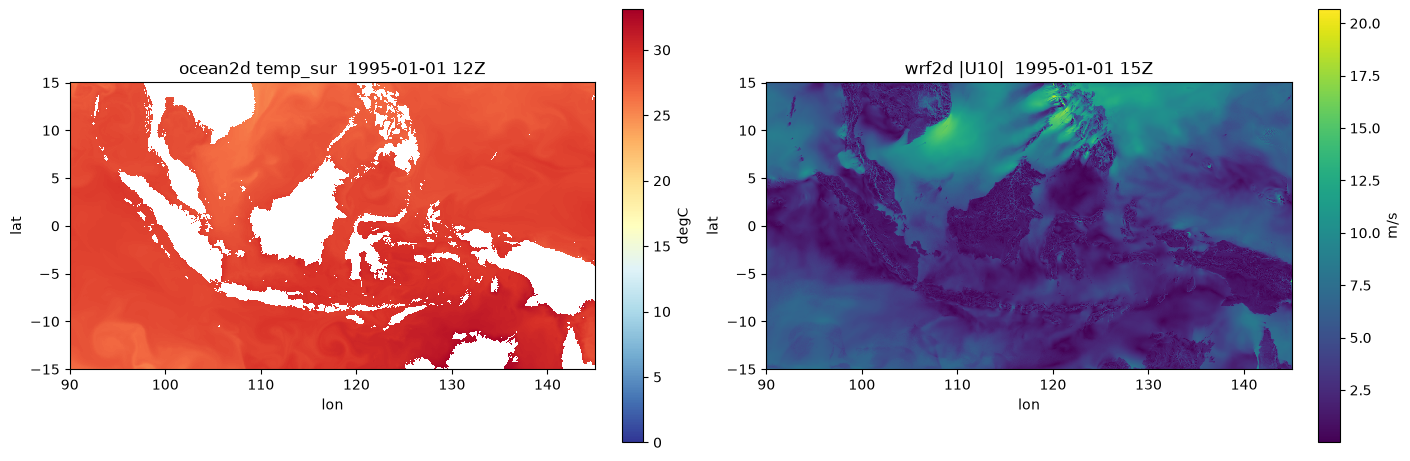

In [4]:
def _lon_lat(ds):
    """Return 2-D lon/lat for pcolormesh."""
    if "lon" in ds and "lat" in ds:
        lon = np.asarray(ds["lon"].values)
        lat = np.asarray(ds["lat"].values)
        if lon.ndim == 1:
            lon, lat = np.meshgrid(lon, lat)
        return lon, lat
    # fallback: ROW/COL as lat/lon axes
    lat1 = np.asarray(ds["ROW"].values)
    lon1 = np.asarray(ds["COL"].values)
    return np.meshgrid(lon1, lat1)


def field2d(da):
    """Squeeze to ROW×COL for plotting."""
    return da.squeeze(drop=True).values


# Ocean2d SST
with xr.open_dataset(SAMPLE["ocean2d"]) as ds:
    lon, lat = _lon_lat(ds)
    sst = field2d(ds["temp_sur"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
ax = axes[0]
pcm = ax.pcolormesh(lon, lat, sst, shading="auto", cmap="RdYlBu_r")
fig.colorbar(pcm, ax=ax, label="degC")
ax.set_title("ocean2d temp_sur  1995-01-01 12Z")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
ax.set_aspect("equal")

# WRF2d wind speed
with xr.open_dataset(SAMPLE["wrf2d"]) as ds:
    lon, lat = _lon_lat(ds)
    u = field2d(ds["U_EASTWARD_10M"])
    v = field2d(ds["V_NORTHWARD_10M"])
    wspd = np.hypot(u, v)

ax = axes[1]
pcm = ax.pcolormesh(lon, lat, wspd, shading="auto", cmap="viridis")
fig.colorbar(pcm, ax=ax, label="m/s")
ax.set_title("wrf2d |U10|  1995-01-01 15Z")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
ax.set_aspect("equal")
plt.show()


### Spatial subset (e.g. Java Sea)

Prefer boolean masks on lat/lon rather than loading multi-day stacks.


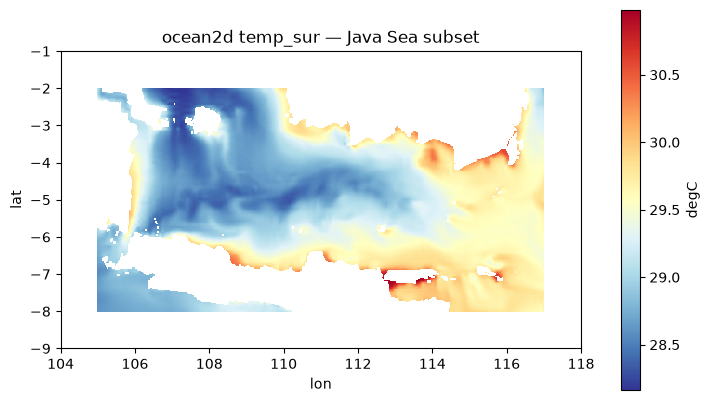

subset finite cells: 78646


In [5]:
# Java Sea–ish box
LON_MIN, LON_MAX = 105.0, 117.0
LAT_MIN, LAT_MAX = -8.0, -2.0

with xr.open_dataset(SAMPLE["ocean2d"]) as ds:
    lon, lat = _lon_lat(ds)
    mask = (lon >= LON_MIN) & (lon <= LON_MAX) & (lat >= LAT_MIN) & (lat <= LAT_MAX)
    sst = field2d(ds["temp_sur"])
    sst_box = np.where(mask, sst, np.nan)

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
pcm = ax.pcolormesh(lon, lat, sst_box, shading="auto", cmap="RdYlBu_r")
fig.colorbar(pcm, ax=ax, label="degC")
ax.set_xlim(LON_MIN - 1, LON_MAX + 1)
ax.set_ylim(LAT_MIN - 1, LAT_MAX + 1)
ax.set_title("ocean2d temp_sur — Java Sea subset")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
ax.set_aspect("equal")
plt.show()

print("subset finite cells:", np.isfinite(sst_box).sum())


### Point time series (nearest lon/lat over one day)

Build a short series from all files in a day folder without `open_mfdataset` (safer for large files).


25 files in /scratch/cawohdcst/data/postprocessed/ocean2d/f19950101
nearest grid: j=396, i=672, lon=106.800, lat=-5.100


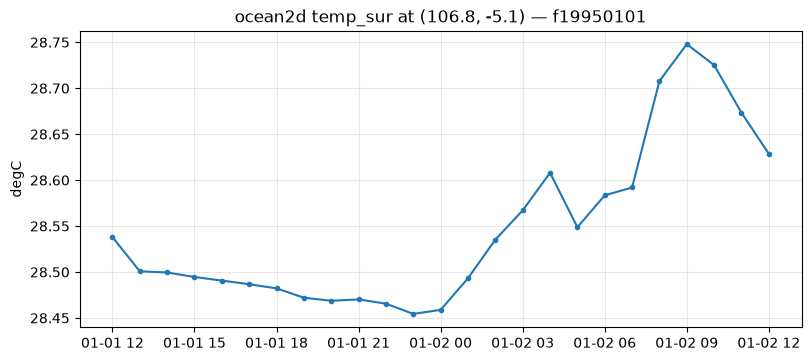

In [7]:
POINT_LON, POINT_LAT = 106.8, -5.1  # near Jakarta / Sunda Strait


def nearest_ij(lon2d, lat2d, lon0, lat0):
    dist2 = (lon2d - lon0) ** 2 + (lat2d - lat0) ** 2
    j, i = np.unravel_index(np.nanargmin(dist2), dist2.shape)
    return int(j), int(i)


day_dir = POST_ROOT / "ocean2d" / DAY
files = sorted(day_dir.glob("inacawo_hindcast_ocean2d_*.nc"))
print(f"{len(files)} files in {day_dir}")

with xr.open_dataset(files[0]) as ds0:
    lon, lat = _lon_lat(ds0)
    j, i = nearest_ij(lon, lat, POINT_LON, POINT_LAT)
    print(f"nearest grid: j={j}, i={i}, lon={lon[j, i]:.3f}, lat={lat[j, i]:.3f}")

times, values = [], []
for fp in files:
    with xr.open_dataset(fp) as ds:
        times.append(ds["TSTEP"].values[0])
        values.append(float(ds["temp_sur"].isel(TSTEP=0, LAY=0, ROW=j, COL=i).values))

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.plot(times, values, marker="o", ms=3)
ax.set_title(f"ocean2d temp_sur at ({POINT_LON}, {POINT_LAT}) — {DAY}")
ax.set_ylabel("degC")
ax.grid(True, alpha=0.3)
plt.show()


### Multi-file open (small window only)

`open_mfdataset` works but each file is large. Keep windows short and use `chunks` / selective `drop_variables` when possible.


In [8]:
# Two consecutive ocean3d times on day1 (12Z and 15Z if present)
o3_dir = POST_ROOT / "ocean3d" / DAY
o3_files = sorted(o3_dir.glob("inacawo_hindcast_ocean3d_*.nc"))[:2]
print("opening:", [p.name for p in o3_files])

ds_mf = xr.open_mfdataset(
    [str(p) for p in o3_files],
    combine="nested",
    concat_dim="TSTEP",
    parallel=False,
)
print(ds_mf)
# Example: TEMP at surface-ish layer (LAY=0 → z≈0)
temp0 = ds_mf["TEMP"].isel(LAY=0)
print("TEMP LAY=0 shape:", temp0.shape)
ds_mf.close()


opening: ['inacawo_hindcast_ocean3d_1995-01-01_12:00:00.nc', 'inacawo_hindcast_ocean3d_1995-01-01_15:00:00.nc']
<xarray.Dataset> Size: 952MB
Dimensions:     (TSTEP: 2, LAY: 9, ROW: 1201, COL: 2201, VAR: 5, DATE-TIME: 2)
Coordinates:
  * TSTEP       (TSTEP) datetime64[ns] 16B 1995-01-01T12:00:00 1995-01-01T15:...
  * LAY         (LAY) float32 36B 0.0 -10.0 -25.0 -50.0 ... -500.0 -1e+03 -2e+03
  * ROW         (ROW) float64 10kB -15.0 -14.97 -14.95 ... 14.95 14.98 15.0
  * COL         (COL) float64 18kB 90.0 90.03 90.05 90.08 ... 145.0 145.0 145.0
Dimensions without coordinates: VAR, DATE-TIME
Data variables:
    TEMP        (TSTEP, LAY, ROW, COL) float32 190MB dask.array<chunksize=(1, 3, 601, 1101), meta=np.ndarray>
    SALT        (TSTEP, LAY, ROW, COL) float32 190MB dask.array<chunksize=(1, 3, 601, 1101), meta=np.ndarray>
    Uearth_RHO  (TSTEP, LAY, ROW, COL) float32 190MB dask.array<chunksize=(1, 3, 601, 1101), meta=np.ndarray>
    Vearth_RHO  (TSTEP, LAY, ROW, COL) float32 190MB das

/tmp/ipykernel_420328/3757925699.py:6: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_mf = xr.open_mfdataset(


### 3-D slice maps — ocean3d TEMP and wrf3d TEMP_AIR


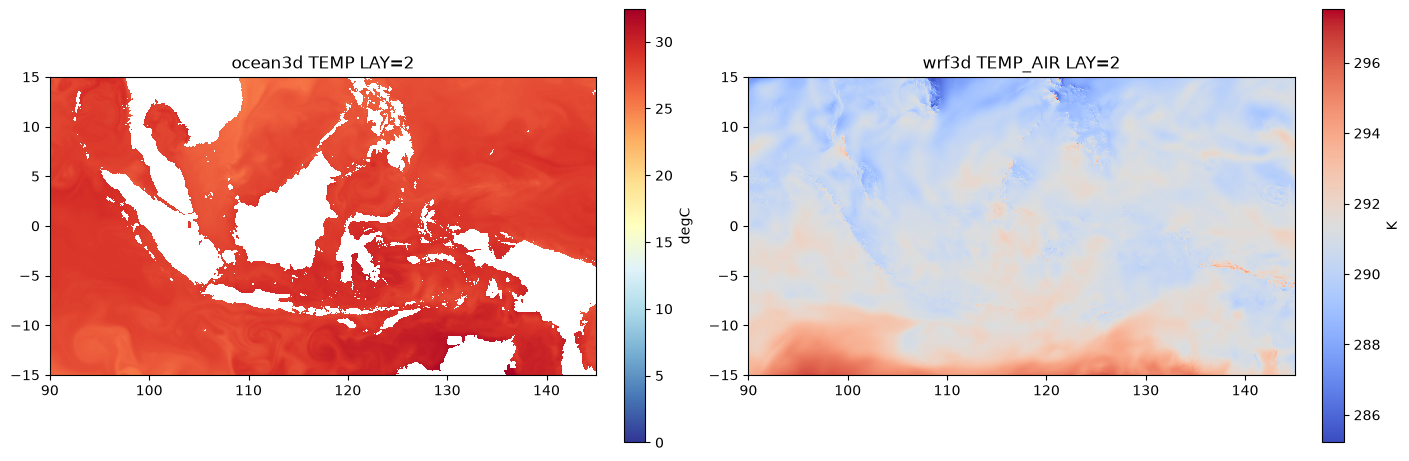

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)

with xr.open_dataset(SAMPLE["ocean3d"]) as ds:
    lon, lat = _lon_lat(ds)
    # LAY index 0 is near-surface (z≈0); deeper layers have larger |z|
    lay = 2  # often ~-25 m depending on file metadata
    temp = field2d(ds["TEMP"].isel(LAY=lay))
    ax = axes[0]
    pcm = ax.pcolormesh(lon, lat, temp, shading="auto", cmap="RdYlBu_r")
    fig.colorbar(pcm, ax=ax, label="degC")
    ax.set_title(f"ocean3d TEMP LAY={lay}")
    ax.set_aspect("equal")

with xr.open_dataset(SAMPLE["wrf3d"]) as ds:
    lon, lat = _lon_lat(ds)
    # LAY indexes selected Pa levels (950…500 hPa)
    lay = 2
    tair = field2d(ds["TEMP_AIR"].isel(LAY=lay))
    ax = axes[1]
    pcm = ax.pcolormesh(lon, lat, tair, shading="auto", cmap="coolwarm")
    fig.colorbar(pcm, ax=ax, label="K")
    ax.set_title(f"wrf3d TEMP_AIR LAY={lay}")
    ax.set_aspect("equal")

plt.show()


### Variable cheat-sheets

**ocean2d** (`EXEC_ID=OCEAN2D-hindcast`): `temp_sur`, `salt_sur`, `u_sur_eastward`, `v_sur_northward`, `zeta`, plus wave fields (`sig_wave_height`, `mean_wave_dir`, `peak_wave_period`, wind-sea / swell partitions, …).

**ocean3d** (`LAY=9` z-levels): `TEMP`, `SALT`, `Uearth_RHO`, `Vearth_RHO`, `W_RHO`.

**wrf2d**: `SEA_SFC_TEMP` (K), `RELHUM_2M`, `U_EASTWARD_10M`, `V_NORTHWARD_10M`, `GUST_SPEED_10M`, `MLCAPE`, `MEAN_SEALEV_PRS`, `VISIBILITY_IN_AIR`, `TOTFLSHRT_PHR`, cloud fractions, `ACCUM_PCP_TOT` (3 h).

**wrf3d** (`LAY=6` pressure levels): `DEWPT_TMP`, `RELHUM`, `U_WIND`, `V_WIND`, `TEMP_AIR`.

Fill value: typically `-9.999e36`.


In [10]:
# Quick inventory of one sample from each stream
for name, path in SAMPLE.items():
    with xr.open_dataset(path) as ds:
        data_vars = [v for v in ds.data_vars if v not in ("TFLAG", "RUNTIME", "lat", "lon", "geographic")]
        print(f"\n=== {name} ({path.name}) ===")
        print("  dims:", {k: int(v) for k, v in ds.dims.items() if k in ("TSTEP", "LAY", "ROW", "COL", "VAR")})
        print("  vars:", ", ".join(data_vars[:12]), ("…" if len(data_vars) > 12 else ""))



=== ocean2d (inacawo_hindcast_ocean2d_1995-01-01_12:00:00.nc) ===
  dims: {'TSTEP': 1, 'LAY': 1, 'ROW': 1201, 'COL': 2201, 'VAR': 20}
  vars: temp_sur, salt_sur, u_sur_eastward, v_sur_northward, zeta, sig_wave_height, mean_wave_dir, peak_wave_dir, mean_wave_len, peak_wave_len, peak_wave_period, wind_sea_swht …

=== ocean3d (inacawo_hindcast_ocean3d_1995-01-01_12:00:00.nc) ===
  dims: {'TSTEP': 1, 'LAY': 9, 'ROW': 1201, 'COL': 2201, 'VAR': 5}
  vars: TEMP, SALT, Uearth_RHO, Vearth_RHO, W_RHO 

=== wrf2d (inacawo_hindcast_wrf2d_1995-01-01_15:00:00.nc) ===
  dims: {'TSTEP': 1, 'LAY': 1, 'ROW': 1201, 'COL': 2201, 'VAR': 13}
  vars: SEA_SFC_TEMP, RELHUM_2M, U_EASTWARD_10M, V_NORTHWARD_10M, GUST_SPEED_10M, MLCAPE, MEAN_SEALEV_PRS, VISIBILITY_IN_AIR, TOTFLSHRT_PHR, LOW_CLOUD_FRACTION, MID_CLOUD_FRACTION, HIGH_CLOUD_FRACTION …

=== wrf3d (inacawo_hindcast_wrf3d_1995-01-01_15:00:00.nc) ===
  dims: {'TSTEP': 1, 'LAY': 6, 'ROW': 1201, 'COL': 2201, 'VAR': 5}
  vars: DEWPT_TMP, RELHUM, U_WIND, V_W

/tmp/ipykernel_420328/3689295537.py:6: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("  dims:", {k: int(v) for k, v in ds.dims.items() if k in ("TSTEP", "LAY", "ROW", "COL", "VAR")})
/tmp/ipykernel_420328/3689295537.py:6: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("  dims:", {k: int(v) for k, v in ds.dims.items() if k in ("TSTEP", "LAY", "ROW", "COL", "VAR")})
/tmp/ipykernel_420328/3689295537.py:6: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a ma